# Groovy on an NVIDIA GPU with TornadoVM (Colab)

Runs the [groovy-tornadovm](https://github.com/paulk-asert/groovy-tornadovm) examples on TornadoVM's
CUDA backend, using a Colab GPU runtime. Everything happens in `bash` cells driven from the normal
Python runtime: no Groovy Jupyter kernel is needed.

**Pick the hardware first** (Runtime → Change runtime type → T4 GPU). Changing the accelerator
later resets the VM and loses everything installed below.

Steps: check the GPU, install JDK 21, download the TornadoVM 8.0.0 CUDA SDK, then build and run the
examples with the companion repo's Gradle build.

In [1]:
# SPDX-License-Identifier: Apache-2.0
# Environment shared by the bash cells below (each %%bash cell inherits the Python kernel's environment)
import os
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'
os.environ['TORNADOVM_HOME'] = '/content/tornadovm-8.0.0-cuda'
os.environ['PATH'] = f"{os.environ['TORNADOVM_HOME']}/bin:{os.environ['JAVA_HOME']}/bin:{os.environ['PATH']}"
# Colab's cgroup layout makes every JVM print [warning][os,container] lines; this silences JVM logging only
os.environ['GRADLE_OPTS'] = '-Xlog:disable'

## 1. Check the GPU

`nvidia-smi`'s "CUDA Version" is the newest runtime the driver supports; `nvcc` shows the installed
toolkit. TornadoVM's CUDA backend compiles kernels at run time with NVRTC, so we also look for that.

In [2]:
%%bash
nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
nvcc --version | tail -2
ls /usr/local/cuda/lib64/ | grep -E '^libnvrtc\.so' | head -3

name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
libnvrtc.so
libnvrtc.so.13
libnvrtc.so.13.0.88


## 2. Install JDK 21

The TornadoVM SDK used here is the `jdk21` build.

In [3]:
%%bash
apt-get -qq update > /dev/null
apt-get -qq install -y openjdk-21-jdk-headless > /dev/null
java -Xlog:disable -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


## 3. Download the TornadoVM 8.0.0 CUDA SDK

From the [8.0.0 release](https://github.com/beehive-lab/TornadoVM/releases/tag/v8.0.0). It unpacks to
`tornadovm-8.0.0-cuda/`. Then ask TornadoVM which devices it can see; we expect the T4.

In [4]:
%%bash
cd /content
[ -d tornadovm-8.0.0-cuda ] || curl -sSL https://github.com/beehive-lab/TornadoVM/releases/download/v8.0.0/tornadovm-8.0.0-jdk21-cuda-linux-amd64.tar.gz | tar xz
tornado --jvm=-Xlog:disable --devices


Number of Tornado drivers: 1
Driver: CUDADriver
  Total number of CUDADriver devices  : 1
  Tornado device=0:0  (DEFAULT)
	CUDA --  [NVIDIA CUDA] -- Tesla T4
		Global Memory Size: 14.6 GB
		Local Memory Size: 48.0 KB
		Workgroup Dimensions: 3
		Total Number of Block Threads: [1024]
		Max WorkGroup Configuration: [1024, 1024, 64]
		Device OpenCL C version: CUDA C 1.0




## 4. Build and run the examples

Clone the companion repo and run the `KernelContext` examples, which work with Groovy 6.0.0.
The first Gradle run downloads Gradle and Groovy, so it takes a while.

`--printKernel` shows the CUDA C that TornadoVM generated from the Groovy bytecode.

In [5]:
%%bash
cd /content
[ -d groovy-tornadovm ] || git clone -q --depth 1 https://github.com/paulk-asert/groovy-tornadovm.git
cd groovy-tornadovm
./gradlew --no-daemon -q :examples:runVectorAdd "-PtornadoFlags=--jvm=-Xlog:disable --printKernel"

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
extern "C" __global__ void VectorAdd_vectorAdd(long long *_kernel_context, unsigned char *_constant_region, unsigned char *_local_region, int *_atomics, unsigned char *a, unsigned char *b, unsigned char *c)
{
  int i;
  float *a_data, *b_data, *c_data;
  i = (int) (blockIdx.x * blockDim.x + threadIdx.x);  // VectorAdd.java:31
  a_data = (float *) (a + 16LL);  // VectorAdd.java:32
  b_data = (float *) (b + 16LL);  // VectorAdd.java:32
  c_data = (float *) (c + 16LL);  // VectorAdd.java:32
  c_data[i] = a_data[i] + b_data[i];  // VectorAdd.java:32
}

c[0..3] = [0.7822289, 0.7311627, 1.250793, 0.984789], mismatches = 0


The Mandelbrot example renders a 3840×3200 image on the GPU (timed over 5 runs after a warm-up run
that includes compiling the kernel), then on the CPU, single-threaded and with a parallel stream, and
compares the results. Colab runtimes have only a couple of CPU cores, so the CPU part takes a minute or two.

In [6]:
%%bash
cd /content/groovy-tornadovm
./gradlew --no-daemon -q :examples:runMandelbrot "-PtornadoFlags=--jvm=-Xlog:disable"

GPU: 16.8 ms/frame
CPU (single thread): 46481.5 ms
CPU (parallel stream, 2 cores): 24990.1 ms
pixels differing GPU vs CPU: 33896 of 12288000 (0.276%)
total iterations: 2541632526


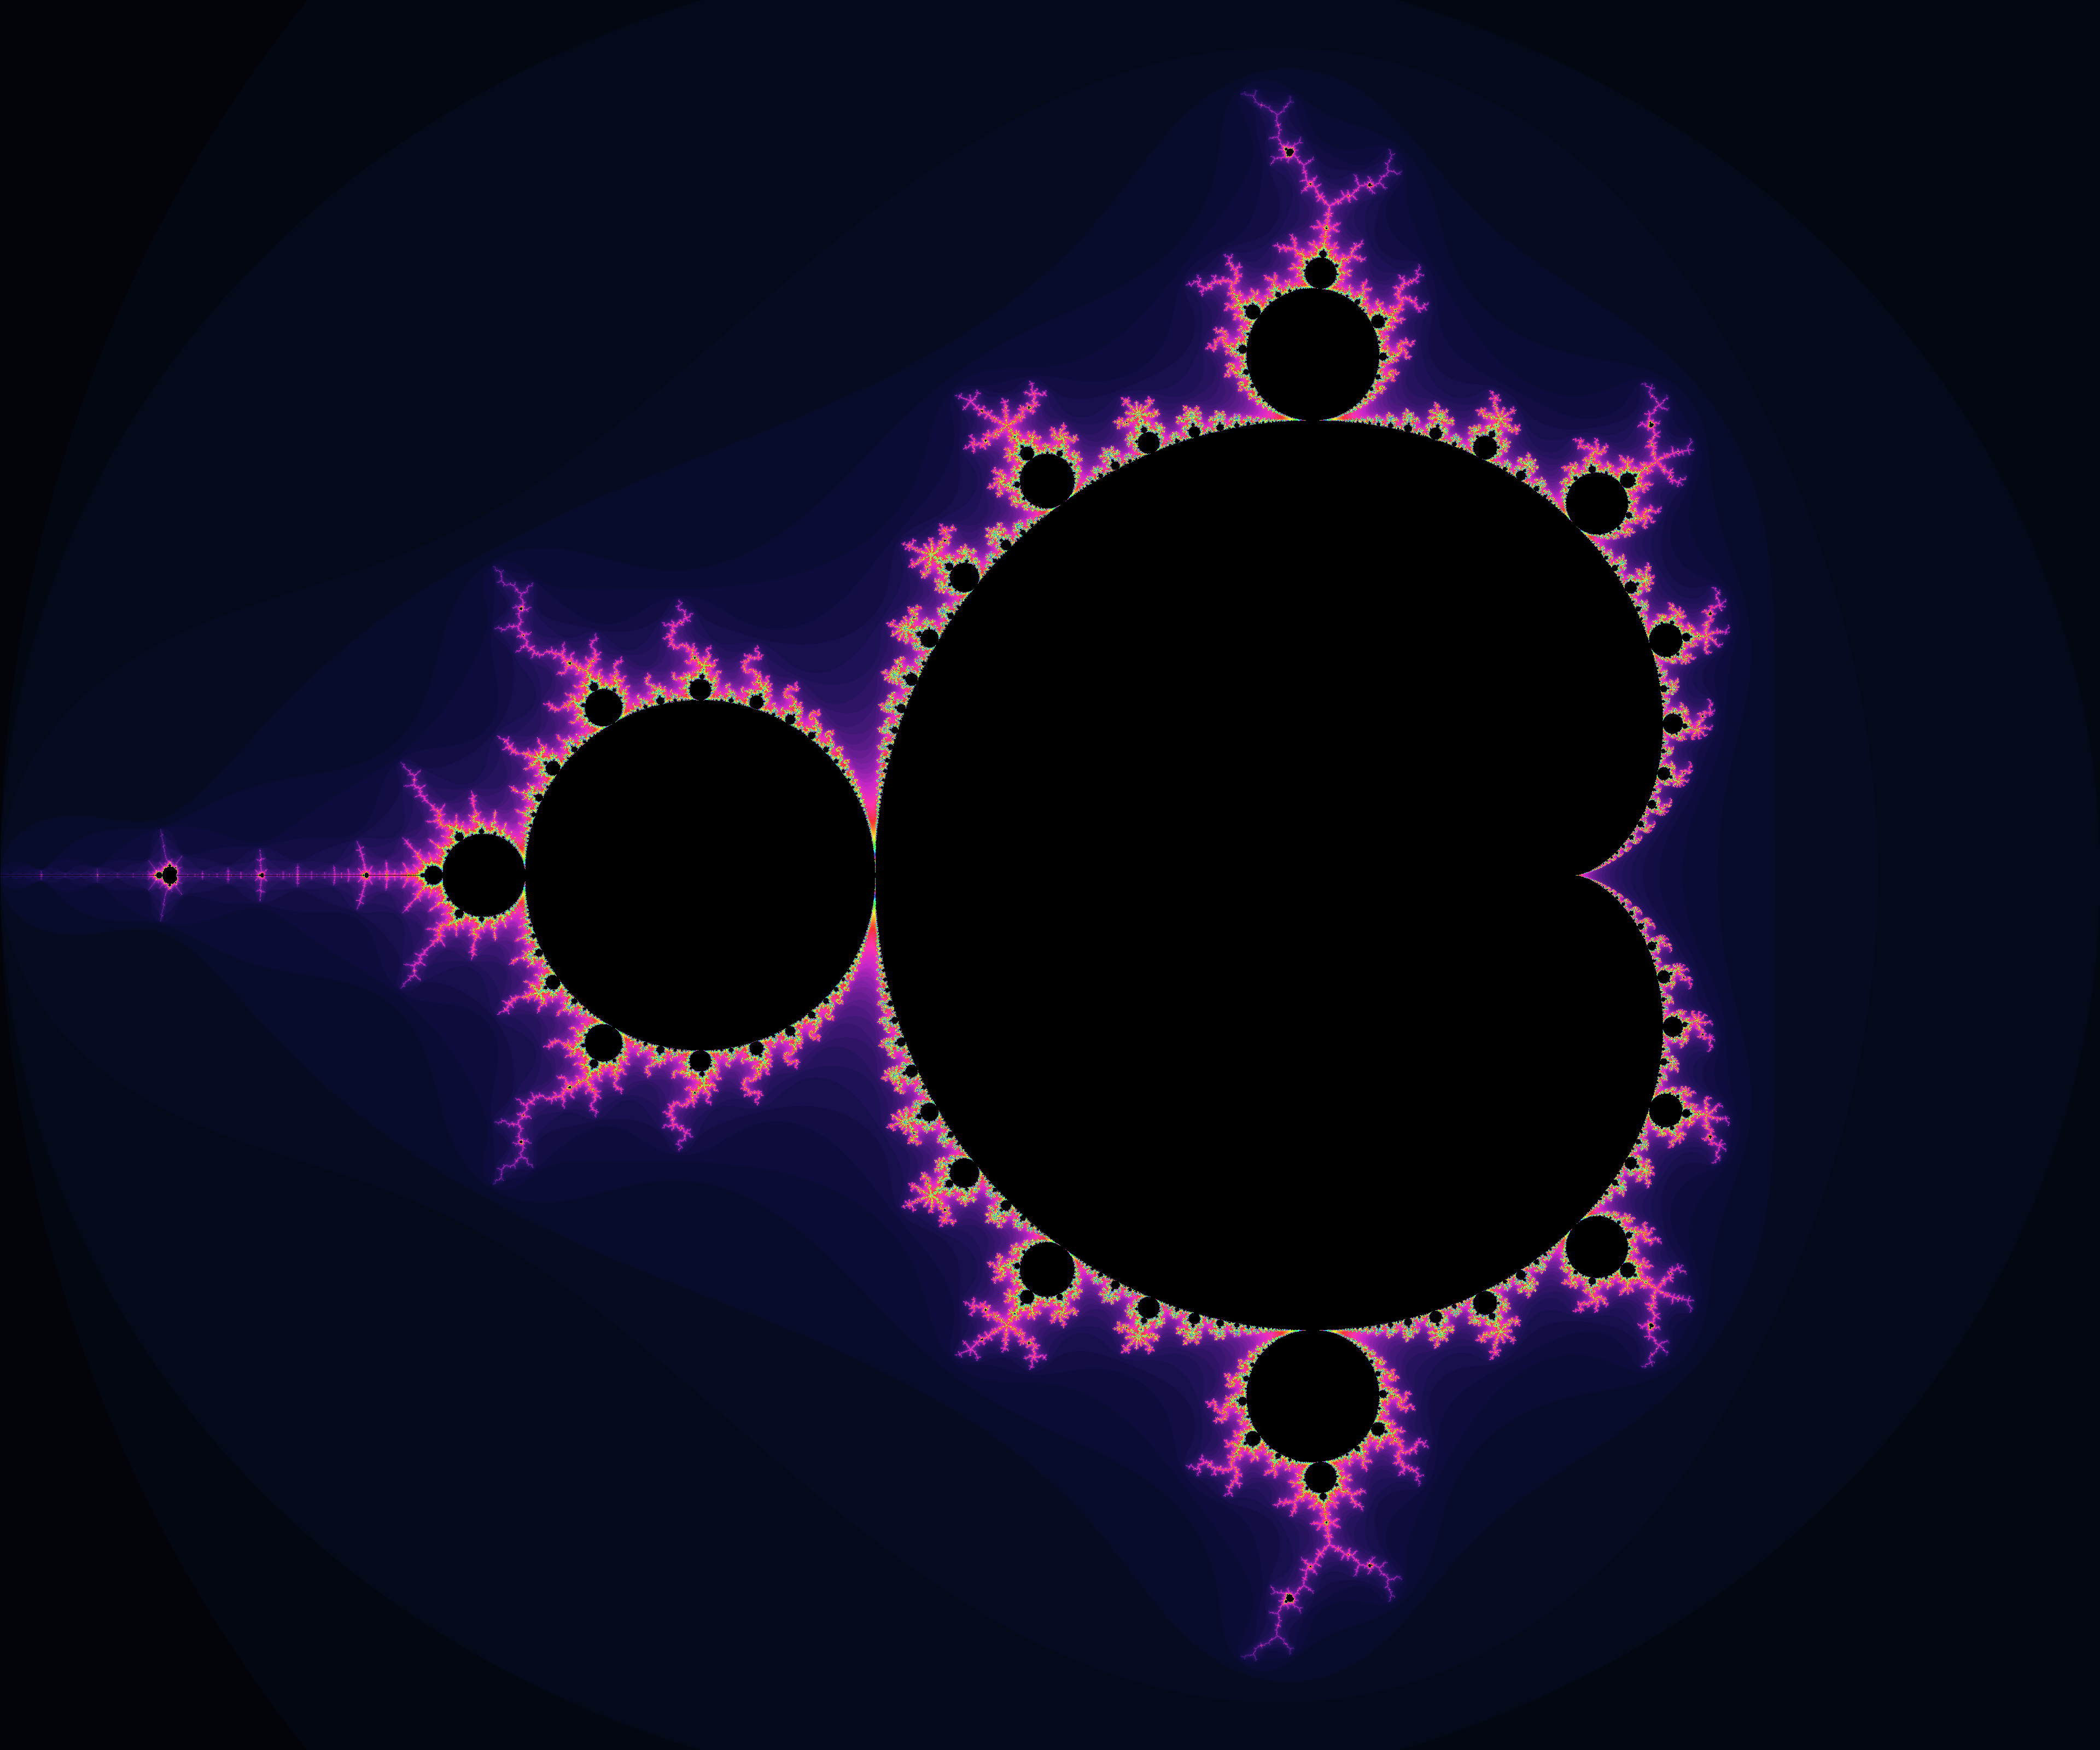

In [7]:
from IPython.display import Image
Image('/content/groovy-tornadovm/examples/build/mandelbrot.png', width=640)

## 5. Experiments

**Double precision.** Apple GPUs have no 64-bit floating point, so on a Mac a Mandelbrot kernel written
with `double` locals and `d`-suffixed literals (which Groovy, unlike `float` literals, doesn't move into
fields) fails with `TC-E4012 this kernel uses double precision, which the device does not support`.
A T4 does support doubles, at a fraction of its float speed. Try copying `Mandelbrot.mandel` as a
`double` version without `@GpuKernel` and compare the two.

**`@Parallel` loops.** The `parallel` examples need a Groovy release with
[GROOVY-12540](https://issues.apache.org/jira/browse/GROOVY-12540),
[GROOVY-12541](https://issues.apache.org/jira/browse/GROOVY-12541) and
[GROOVY-12542](https://issues.apache.org/jira/browse/GROOVY-12542). Once one is available, set its
version below and run the cell.

In [8]:
%%bash
# GROOVY_VERSION=<a Groovy release with the fixes above>
# cd /content/groovy-tornadovm
# ./gradlew --no-daemon -q -PwithParallel -PgroovyVersion=$GROOVY_VERSION \
#     :parallel:runVectorAddParallel :parallel:runMandelbrotParallel "-PtornadoFlags=--jvm=-Xlog:disable"